In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [2]:
df = pd.read_csv(
    "AKiD_cardinal_vowels-stressed.csv",
    sep=";",
    decimal=",",
)

In [3]:
df

,ID,Group,Sex,Age,Vowel,Stress,F1_midpoint,F2_midpoint,F3_midpoint
0,DEM01,DEM,F,82,a,ST,731.457453,1612.167340,2879.295031
1,DEM01,DEM,F,82,a,ST,885.550791,1674.669069,3035.152310
2,DEM01,DEM,F,82,a,ST,854.663124,1582.884093,2896.653144
3,DEM01,DEM,F,82,a,ST,830.715058,1595.793368,2928.387673
4,DEM01,DEM,F,82,a,ST,799.431314,1588.578816,2363.990597
...,...,...,...,...,...,...,...,...,...
3166,HE10,HE,F,61,i,ST,361.930801,2802.832592,3590.120060
3167,HE10,HE,F,61,i,ST,430.549933,2834.941372,3327.100069
3168,HE10,HE,F,61,i,ST,441.155417,2753.688447,3088.867778
3169,HE10,HE,F,61,a,ST,900.193273,1341.440659,1639.856220


In [4]:
palette_group = {"HA": "#4C72B0", "HE": "#55A868", "DEM": "#C44E52"}
palette_vowel = {"a": "#E41A1C", "i": "#377EB8", "u": "#4DAF4A"}

In [5]:
df["Group"] = pd.Categorical(df["Group"], categories=palette_group, ordered=True)
df["Vowel"] = pd.Categorical(df["Vowel"], categories=palette_vowel, ordered=True)

In [6]:
print("Groups:", df["Group"].value_counts().to_dict())
print("Vowels:", df["Vowel"].value_counts().to_dict())
assert df["Group"].notna().all() and df["Vowel"].notna().all()

os.makedirs("figs", exist_ok=True)
sns.set_theme(style="whitegrid", context="talk")

Groups: {'HE': 1317, 'DEM': 1092, 'HA': 762}
Vowels: {'a': 1328, 'u': 925, 'i': 918}


In [7]:
def is_outlier(row):
    v, f1, f2 = row["Vowel"], row["F1_midpoint"], row["F2_midpoint"]
    if v == "a":
        return not (400 <= f1 <= 1300 and 700 <= f2 <= 2200)
    if v == "i":
        return not (200 <= f1 <= 700 and 1200 <= f2 <= 3300)
    if v == "u":
        return not (200 <= f1 <= 800 and 400 <= f2 <= 3000)
    return True

before = len(df)
df = df[~df.apply(is_outlier, axis=1)].copy()
print(f"Deleted: {before - len(df)}. Left: {len(df)}")

Deleted: 27. Left: 3144


In [8]:
def draw_ellipse(ax, x, y, color, n_std=1.5):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    if not np.all(np.isfinite(cov)):
        return
    vals, vecs = np.linalg.eigh(cov)
    i = vals.argsort()[::-1]
    vals, vecs = vals[i], vecs[:, i]
    angle = np.degrees(np.arctan2(*vecs[::-1, 0]))
    w, h = 2 * n_std * np.sqrt(np.maximum(vals, 0))
    ax.add_patch(Ellipse((x.mean(), y.mean()), w, h, angle=angle,
                         facecolor=color, alpha=0.12, edgecolor=color, lw=1.2))

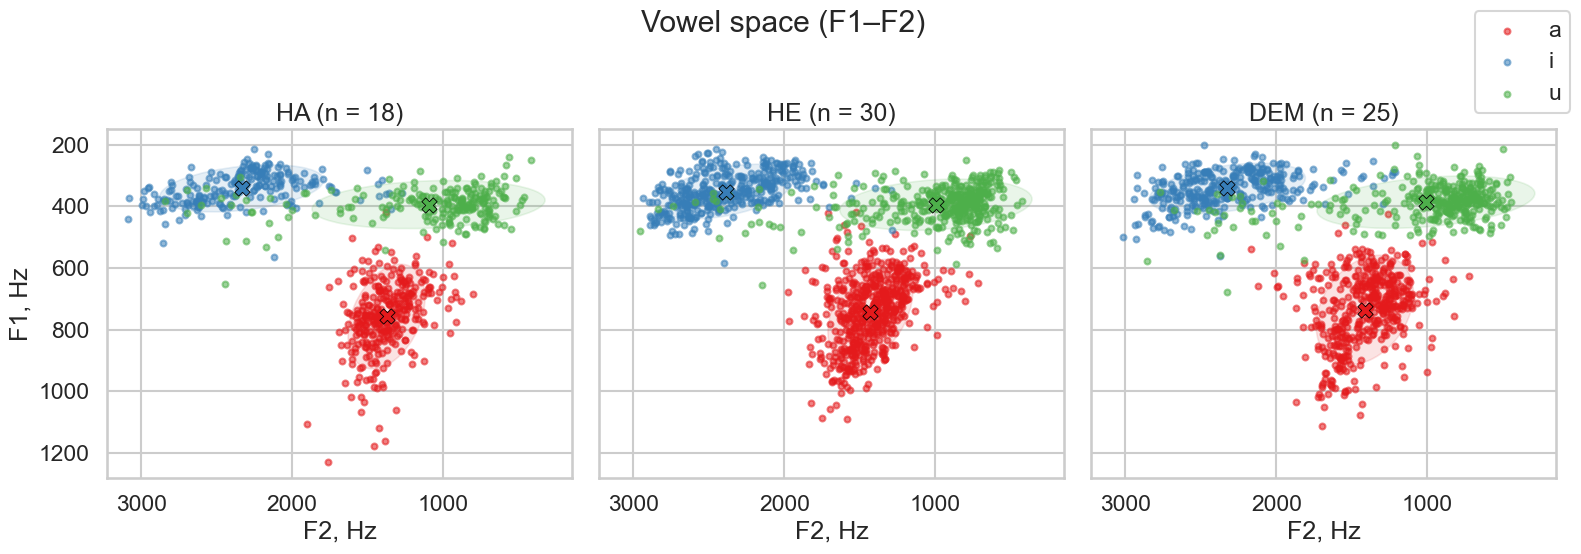

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
for ax, grp in zip(axes, palette_group):
    sub = df[df["Group"] == grp]
    for v in palette_vowel:
        s = sub[sub["Vowel"] == v]
        if s.empty:
            continue
        c = palette_vowel[v]
        ax.scatter(s["F2_midpoint"], s["F1_midpoint"],
                   s=18, alpha=0.55, color=c, label=v)
        draw_ellipse(ax, s["F2_midpoint"], s["F1_midpoint"], c)
        ax.scatter(s["F2_midpoint"].mean(), s["F1_midpoint"].mean(),
                   s=120, marker="X", color=c, edgecolor="black", lw=0.6, zorder=5)
    ax.invert_xaxis(); ax.invert_yaxis()
    ax.set(title=f"{grp} (n = {sub['ID'].nunique()})", xlabel="F2, Hz")
axes[0].set_ylabel("F1, Hz")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right")
fig.suptitle("Vowel space (F1–F2)", y=1.02)
plt.tight_layout()

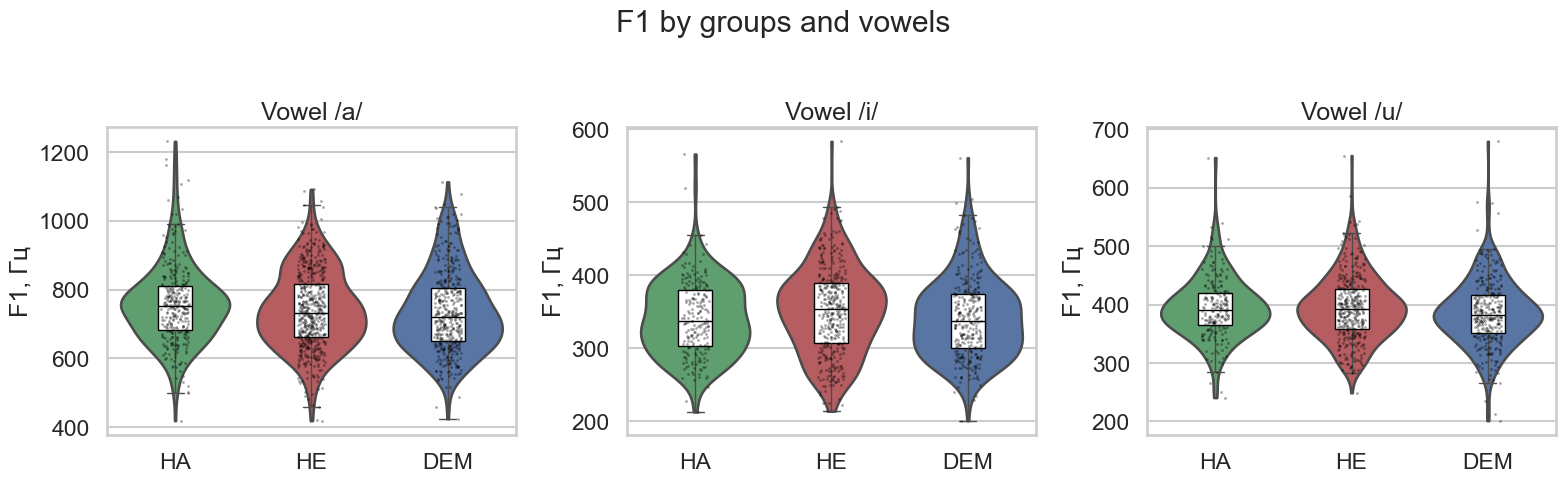

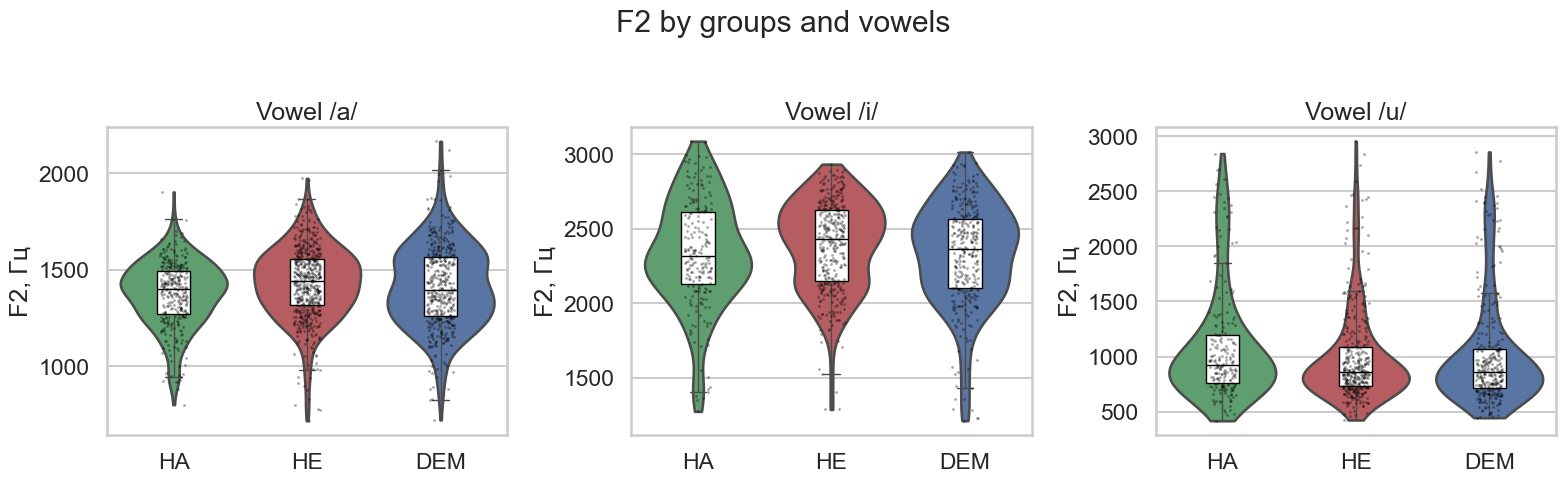

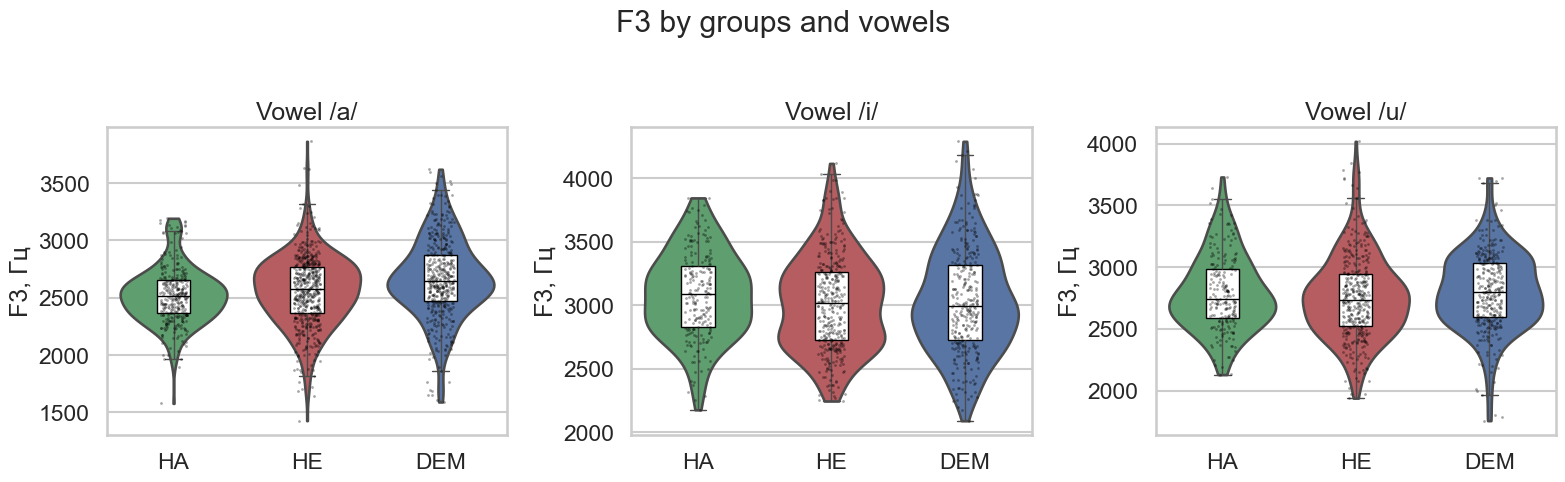

In [10]:
for f in ["F1_midpoint", "F2_midpoint", "F3_midpoint"]:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, v in zip(axes, palette_vowel):
        sub = df[df["Vowel"] == v]
        kw = dict(data=sub, x="Group", y=f, hue="Group",
                  palette=palette_group, dodge=False, legend=False, ax=ax)

        sns.violinplot(inner=None, cut=0, **kw)
        sns.boxplot(width=0.25, showfliers=False, **kw,
                    boxprops={"facecolor": "white", "edgecolor": "black"},
                    medianprops={"color": "black"})
        sns.stripplot(data=sub, x="Group", y=f,
                      color="black", size=2, alpha=0.35, ax=ax)

        ax.set(title=f"Vowel /{v}/", xlabel="",
               ylabel=f.replace("_midpoint", ", Гц"))

    fig.suptitle(f"{f.replace('_midpoint', '')} by groups and vowels", y=1.02)
    plt.tight_layout()

In [11]:
def dispersion_per_speaker(df, f1="F1_midpoint", f2="F2_midpoint"):
    iqr = lambda x: np.subtract(*np.percentile(x, [75, 25]))
    return (df.groupby(["ID", "Group", "Vowel"])
              .agg(F1_sd=(f1, "std"), F2_sd=(f2, "std"),
                   F1_iqr=(f1, iqr), F2_iqr=(f2, iqr))
              .reset_index())

disp_raw = dispersion_per_speaker(df)

disp_speaker = (disp_raw.groupby(["ID", "Group"])[["F1_sd", "F2_sd"]]
                         .mean().reset_index())

F1_sd: Kruskal–Wallis H = 2.07, p = 0.3550
F2_sd: Kruskal–Wallis H = 3.48, p = 0.1752


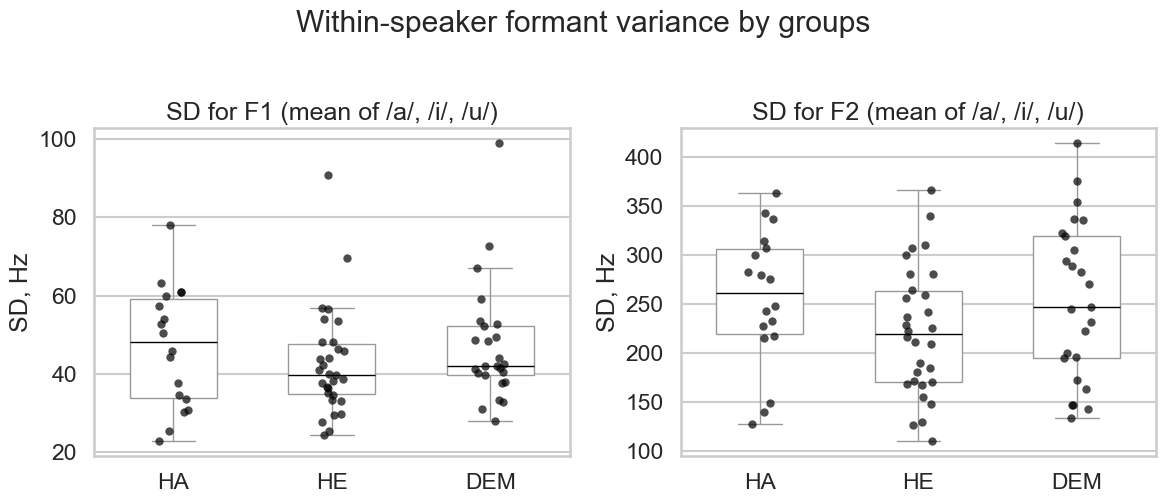

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["F1_sd", "F2_sd"]):
    sns.boxplot(data=disp_speaker, x="Group", y=col,
                color="white", width=0.55, showfliers=False, ax=ax,
                medianprops={"color": "black"})
    sns.stripplot(data=disp_speaker, x="Group", y=col,
                  color="black", size=6, alpha=0.7, ax=ax)
    ax.set(title=f"SD for {col[:2]} (mean of /a/, /i/, /u/)",
           xlabel="", ylabel="SD, Hz")

    groups = [disp_speaker.loc[disp_speaker["Group"] == g, col].dropna()
              for g in palette_group]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) > 1:
        H, p = stats.kruskal(*groups)
        print(f"{col}: Kruskal–Wallis H = {H:.2f}, p = {p:.4f}")

fig.suptitle("Within-speaker formant variance by groups", y=1.02)
plt.tight_layout()

In [13]:
X = (df.pivot_table(index=["ID", "Group"], columns="Vowel",
                    values=["F1_midpoint", "F2_midpoint", "F3_midpoint"],
                    observed=True)
       .reset_index())
X.columns = ["_".join(map(str, c)).strip("_") for c in X.columns]

feature_cols = [f"{f}_midpoint_{v}"
                for f in ("F1", "F2", "F3")
                for v in palette_vowel]

In [14]:
mask = X[feature_cols].notna().all(axis=1)
Xc = X.loc[mask]

In [15]:
pca = PCA(n_components=min(len(feature_cols), len(Xc)))
scores = pca.fit_transform(StandardScaler().fit_transform(Xc[feature_cols]))
evr = pca.explained_variance_ratio_

sdf = pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"])
sdf["ID"] = Xc["ID"].values
sdf["Group"] = Xc["Group"].astype(str).values

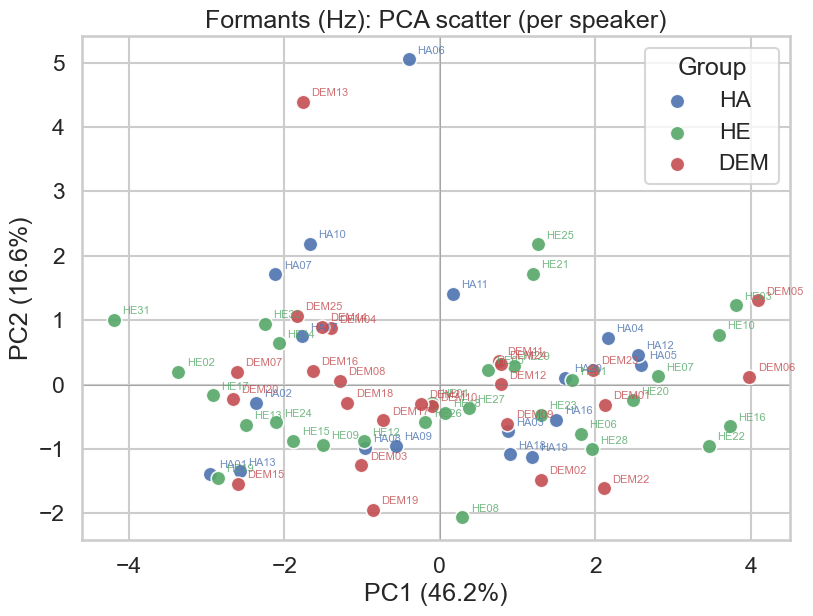

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for grp in palette_group:
    sub = sdf[sdf["Group"] == grp]
    if sub.empty:
        continue
    c = palette_group[grp]
    ax.scatter(sub["PC1"], sub["PC2"], s=110, color=c, label=grp,
               edgecolor="white", lw=1.2, alpha=0.9)
    for _, r in sub.iterrows():
        ax.annotate(r["ID"], (r["PC1"], r["PC2"]),
                    textcoords="offset points", xytext=(6, 4),
                    fontsize=8, color=c, alpha=0.8)

ax.axhline(0, color="grey", lw=0.6, alpha=0.6)
ax.axvline(0, color="grey", lw=0.6, alpha=0.6)
ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
ax.set_title("Formants (Hz): PCA scatter (per speaker)")
ax.legend(title="Group")

fig.tight_layout()
plt.show()

In [17]:
df_lmm = df.copy()
df_lmm["Group"] = pd.Categorical(df_lmm["Group"].astype(str), categories=["HE", "HA", "DEM"])
df_lmm["Vowel"] = pd.Categorical(df_lmm["Vowel"].astype(str), categories=["a", "i", "u"])
df_lmm["F1_z"]  = (df_lmm["F1_midpoint"] - df_lmm["F1_midpoint"].mean()) / df_lmm["F1_midpoint"].std()

result_f1 = smf.mixedlm(
    "F1_z ~ Group + Vowel",
    data=df_lmm,
    groups=df_lmm["ID"],
    re_formula="~Vowel",
).fit(reml=True, method="powell")

print(result_f1.summary())
print("Converged:", result_f1.converged)
print("RE covariance diag:", np.diag(result_f1.cov_re))

                 Mixed Linear Model Regression Results
Model:                  MixedLM      Dependent Variable:      F1_z     
No. Observations:       3144         Method:                  REML     
No. Groups:             73           Scale:                   0.0709   
Min. group size:        33           Log-Likelihood:          -546.5519
Max. group size:        53           Converged:               Yes      
Mean group size:        43.1                                           
-----------------------------------------------------------------------
                            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    1.084    0.058  18.795 0.000  0.971  1.197
Group[T.HA]                 -0.027    0.049  -0.560 0.576 -0.124  0.069
Group[T.DEM]                -0.049    0.043  -1.134 0.257 -0.135  0.036
Vowel[T.i]                  -1.944    0.042 -46.543 0.000 -2.026 -1.862
Vowel[T.u

In [18]:
X = (df.pivot_table(index=["ID", "Group"], columns="Vowel",
                    values=["F1_midpoint", "F2_midpoint", "F3_midpoint"],
                    observed=True)
       .reset_index())
X.columns = ["_".join(map(str, c)).strip("_") for c in X.columns]

feature_cols = [f"{f}_midpoint_{v}"
                for f in ("F1", "F2", "F3")
                for v in palette_vowel]

mask = X[feature_cols].notna().all(axis=1)
Xc = X.loc[mask]

X_feat = Xc[feature_cols].values
X_scaled = StandardScaler().fit_transform(X_feat)

In [19]:
true_labels = Xc["Group"].astype(str).values

In [20]:
km = KMeans(n_clusters=3, n_init=50, random_state=42)
km_labels = km.fit_predict(X_scaled)

ari_km = adjusted_rand_score(true_labels, km_labels)
nmi_km = normalized_mutual_info_score(true_labels, km_labels)
sil_km = silhouette_score(X_scaled, km_labels)

print(ari_km, nmi_km, sil_km)

0.008220722768855828 0.03194005278290908 0.25975358808307136


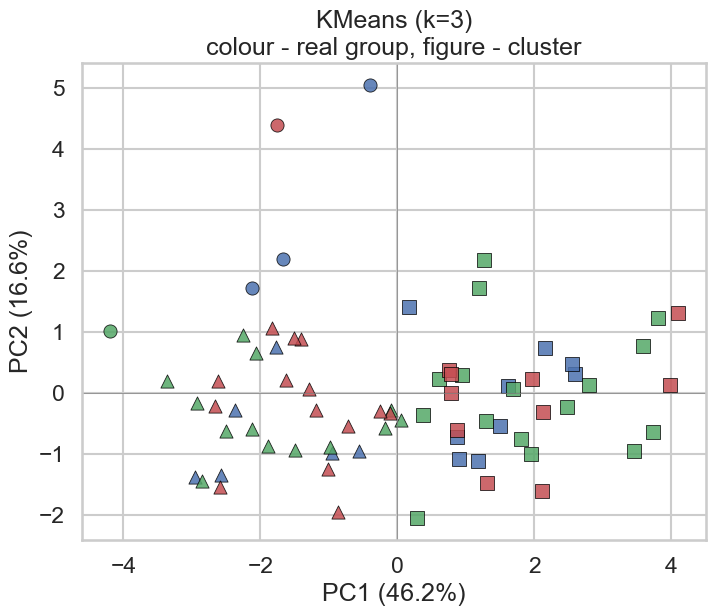

In [21]:
pca = PCA(n_components=2, random_state=42)
scores = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for grp in palette_group:
    for cl in sorted(set(km_labels)):
        mask = (true_labels == grp) & (km_labels == cl)
        if not mask.any():
            continue
        marker = ["o", "s", "^"][cl % 3]
        ax.scatter(scores[mask, 0], scores[mask, 1],
                   s=90, marker=marker,
                   color=palette_group[grp],
                   edgecolor="black", linewidth=0.6, alpha=0.85)

ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"PC1 ({evr[0]:.1%})")
ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
ax.set_title("KMeans (k=3)\ncolour - real group, figure - cluster")

fig.tight_layout()
plt.show()